# Main benchmark: five world models on Two-Rooms

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/latent-horizon/pytorch-world/blob/main/examples/comparisons/main_benchmark.ipynb)

One task, one dataset, five world models, each trained with its own recipe and planned with its own planner:

| model | encoder | trained with | plans with |
|---|---|---|---|
| [LeWM](../action/lewm.ipynb) | ViT, end to end | next-embedding MSE + SIGReg | CEM |
| [PLDM](../action/pldm.ipynb) | CNN, end to end | multi-step prediction + VICReg, smoothness, inverse dynamics | CEM |
| [DINO-WM](../action/dinowm.ipynb) | DINOv2 ViT-S/14, frozen | next-patch MSE | CEM |
| V-JEPA 2-AC | V-JEPA 2.1 ViT-B, frozen | teacher forcing + 2-step rollout, ℓ1 | CEM |
| [TD-MPC2](../action/tdmpc2.ipynb) | CNN, end to end | TD learning on hindsight goals | MPPI |

The task is PLDM's Two-Rooms, from 64×64 pixels, with goal images.

In [ ]:
import importlib.util

if importlib.util.find_spec("torch_world") is None:  # on Colab
    %pip install -q "torch-world[examples]" timm einops

In [2]:
import time

import torch
from torch.utils.data import DataLoader

from torch_world import evaluation, plots
from torch_world.datasets import TrajectoryDataset
from torch_world.envs import TwoRooms
from torch_world.models import DINOWM, PLDM, TDMPC2, LeWM, PLDMEncoder, RoboJEPA
from torch_world.models.tdmpc import pixel_encoder
from torch_world.nn import CLSEncoder, PatchTokens, VideoTokens
from torch_world.planning import CEM, MPPI
from torch_world.utils import fit

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"

## Data
A point wanders through two rooms joined by a door, keeping its previous action 80% of the time: 1024 episodes of 65 steps, no rewards, no expert. Every model trains on the same episodes, cut into windows of the length its recipe uses.

In [3]:
data = TwoRooms(batch_size=1024, device=device).collect(65, generator=torch.Generator().manual_seed(0))


def loader(window):
    return DataLoader(TrajectoryDataset(data, window=window), batch_size=128, shuffle=True, drop_last=True)

## Models
Small versions of each, with predictors of the same depth. The frozen encoders see 4×4 patches of each frame.

In [4]:
predictor = dict(depth=4, num_heads=4, head_dim=32, mlp_dim=512)
models = {
    "LeWM": LeWM(CLSEncoder(img_size=64, patch_size=8, embed_dim=128, depth=4, num_heads=4), action_dim=2, embed_dim=128, proj_dim=512, lamb=0.05, **predictor),
    "PLDM": PLDM(PLDMEncoder(img_size=64, latent_dim=128), action_dim=2, latent_dim=128),
    "DINO-WM": DINOWM(PatchTokens.from_hub("dinov2_vits14", size=56), num_patches=16, embed_dim=384, action_dim=2, **predictor),
    "V-JEPA 2-AC": RoboJEPA(embed_dim=768, action_dim=2, encoder=VideoTokens.from_hub("vjepa2_1_vit_base_384", size=64), predictor_dim=256, depth=4, num_heads=4),
    "TD-MPC2": TDMPC2(pixel_encoder(in_channels=6), action_dim=2, latent_dim=512, mlp_dim=512, discount=TDMPC2.episode_discount(60)),
}
for name, model in models.items():
    print(f"{name:12s} {sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6:5.2f}M trainable parameters")

/clusterhome/kleyton/pytorch-world-roadmap-20261022/pydeps/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


LeWM          2.34M trainable parameters
PLDM          0.54M trainable parameters
DINO-WM       2.45M trainable parameters
V-JEPA 2-AC   3.56M trainable parameters
TD-MPC2       4.86M trainable parameters


TD-MPC2 learns from rewards, so it gets goals by hindsight: its input is the frame and the goal image stacked on channels, the goal is the last frame of the window or of another window, and the reward is minus the distance to the goal.

In [5]:
def hindsight(batch):
    pixels, states = batch["pixels"], batch["states"]  # (B, 8, ...)
    B = len(pixels)
    same = torch.rand(B, device=device) < 0.5
    other = torch.where(same, torch.arange(B, device=device), torch.randperm(B, device=device))
    goal_pixels, goal_states = pixels[other, -1], states[other, -1]
    obs = torch.cat([pixels[:, :4], goal_pixels[:, None].expand(-1, 4, -1, -1, -1)], dim=2)
    rewards = -(states[:, 1:4] - goal_states[:, None]).norm(dim=-1)
    return obs, batch["actions"][:, :3], rewards

## Train
Each model gets 5 epochs of its own windows: 4 frames for the JEPA-style models, PLDM's 17-frame open-loop unrolls, and 8-frame windows for TD-MPC2's hindsight goals.

LeWM           5.6 min


PLDM          13.8 min


DINO-WM        7.5 min


/clusterhome/kleyton/.local/share/uv/python/cpython-3.12.13-linux-aarch64-gnu/lib/python3.12/contextlib.py:105: FutureWarning: `torch.backends.cuda.sdp_kernel()` is deprecated. In the future, this context manager will be removed. Please see `torch.nn.attention.sdpa_kernel()` for the new context manager, with updated signature.
  self.gen = func(*args, **kwds)


V-JEPA 2-AC   25.4 min


TD-MPC2        3.1 min


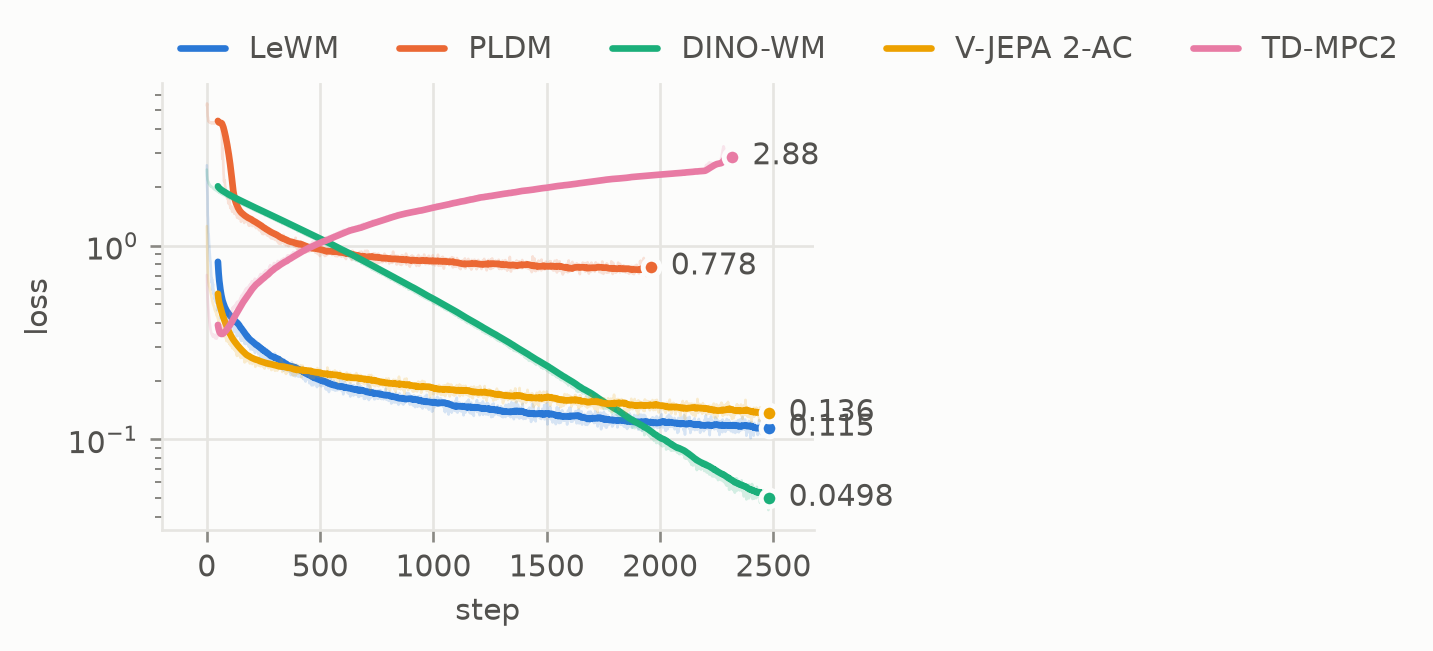

In [6]:
v_jepa = models["V-JEPA 2-AC"]
tdmpc2 = models["TD-MPC2"]
recipes = {
    "LeWM": dict(window=4),
    "PLDM": dict(window=17, lr=1e-3, weight_decay=0),
    "DINO-WM": dict(window=4),
    "V-JEPA 2-AC": dict(window=4, inputs=lambda b: (v_jepa.encode(b["pixels"]), b["actions"])),
    "TD-MPC2": dict(window=8, inputs=hindsight, lr=3e-4, clip=20, step=tdmpc2.update_target),
}
logs, minutes = {}, {}
for name, model in models.items():
    recipe = dict(recipes[name])
    tic = time.time()
    logs[name] = fit(model.to(device), loader(recipe.pop("window")), epochs=5, **recipe)["loss"]
    minutes[name] = (time.time() - tic) / 60
    print(f"{name:12s} {minutes[name]:5.1f} min")
plots.curves(logs, smooth=50)

## Evaluate
32 tasks with the goal in the same room (short) and 32 with the goal in the other room (long: through the door), 60 steps each. An episode succeeds when it comes within 0.1 of the goal at any step, as in LeWM's and PLDM's protocols; the interval is the 95% Wilson interval.

In [7]:
cem = CEM(horizon=8, action_dim=2, num_samples=128, num_elites=16, iterations=5, bounds=(-1, 1), objective="path")
mppi = MPPI(horizon=3, action_dim=2, num_samples=256, num_elites=32, num_pi_trajs=12, iterations=4)
env = TwoRooms(batch_size=32, device=device)


def policies(goal_images):
    out = {name: evaluation.goal_policy(models[name], cem, goal_images) for name in ["LeWM", "PLDM", "DINO-WM", "V-JEPA 2-AC"]}
    mppi.reset()
    out["TD-MPC2"] = lambda obs: mppi(tdmpc2, tdmpc2.encode(torch.cat([obs, goal_images], dim=1)[:, None]))[:, 0]
    out["random actions"] = evaluation.random_policy(env)
    return out


results = {}
for task, same_room in [("same room", True), ("other room", False)]:
    start, goal = env.tasks(torch.Generator().manual_seed(1), same_room=same_room)
    results[task] = evaluation.goal_reaching(env, policies(env.render(goal)), start, goal, steps=60, success="reached")
    print(f"== {task}\n{results[task]}")

/clusterhome/kleyton/.local/share/uv/python/cpython-3.12.13-linux-aarch64-gnu/lib/python3.12/contextlib.py:105: FutureWarning: `torch.backends.cuda.sdp_kernel()` is deprecated. In the future, this context manager will be removed. Please see `torch.nn.attention.sdpa_kernel()` for the new context manager, with updated signature.
  self.gen = func(*args, **kwds)


== same room
                          success  reached   steps  final distance  progress     SPL  smoothness  ms / step
LeWM               78% [61%, 89%]      78%    2.16          0.0249     0.861   0.169       0.394   1.22e+03
PLDM             100% [89%, 100%]     100%    2.81          0.0233     0.931   0.276       0.301       22.5
DINO-WM            97% [84%, 99%]      97%    4.84          0.0442     0.842   0.218       0.439   1.73e+04
V-JEPA 2-AC        88% [72%, 95%]      88%    2.79           0.019     0.885   0.251       0.342   4.18e+04
TD-MPC2             19% [9%, 35%]      22%       1           0.475    -0.573  0.0453       0.516       17.8
random actions     56% [39%, 72%]      56%    22.9           0.375   -0.0898  0.0374        1.05     0.0345


== other room
                          success  reached   steps  final distance  progress     SPL  smoothness  ms / step
LeWM               34% [20%, 52%]      34%    4.91           0.537  0.000539   0.125       0.346   1.22e+03
PLDM               88% [72%, 95%]      88%     6.5          0.0285     0.952   0.347       0.323       22.5
DINO-WM            28% [16%, 45%]      28%    8.22           0.438     0.178  0.0896       0.413   1.73e+04
V-JEPA 2-AC        44% [28%, 61%]      44%    6.86           0.167     0.525   0.185       0.436   4.18e+04
TD-MPC2              0% [0%, 11%]       0%     nan           0.668    -0.268       0       0.525       14.2
random actions       3% [1%, 16%]       3%      19           0.611   0.00976 0.00256        1.05     0.0345


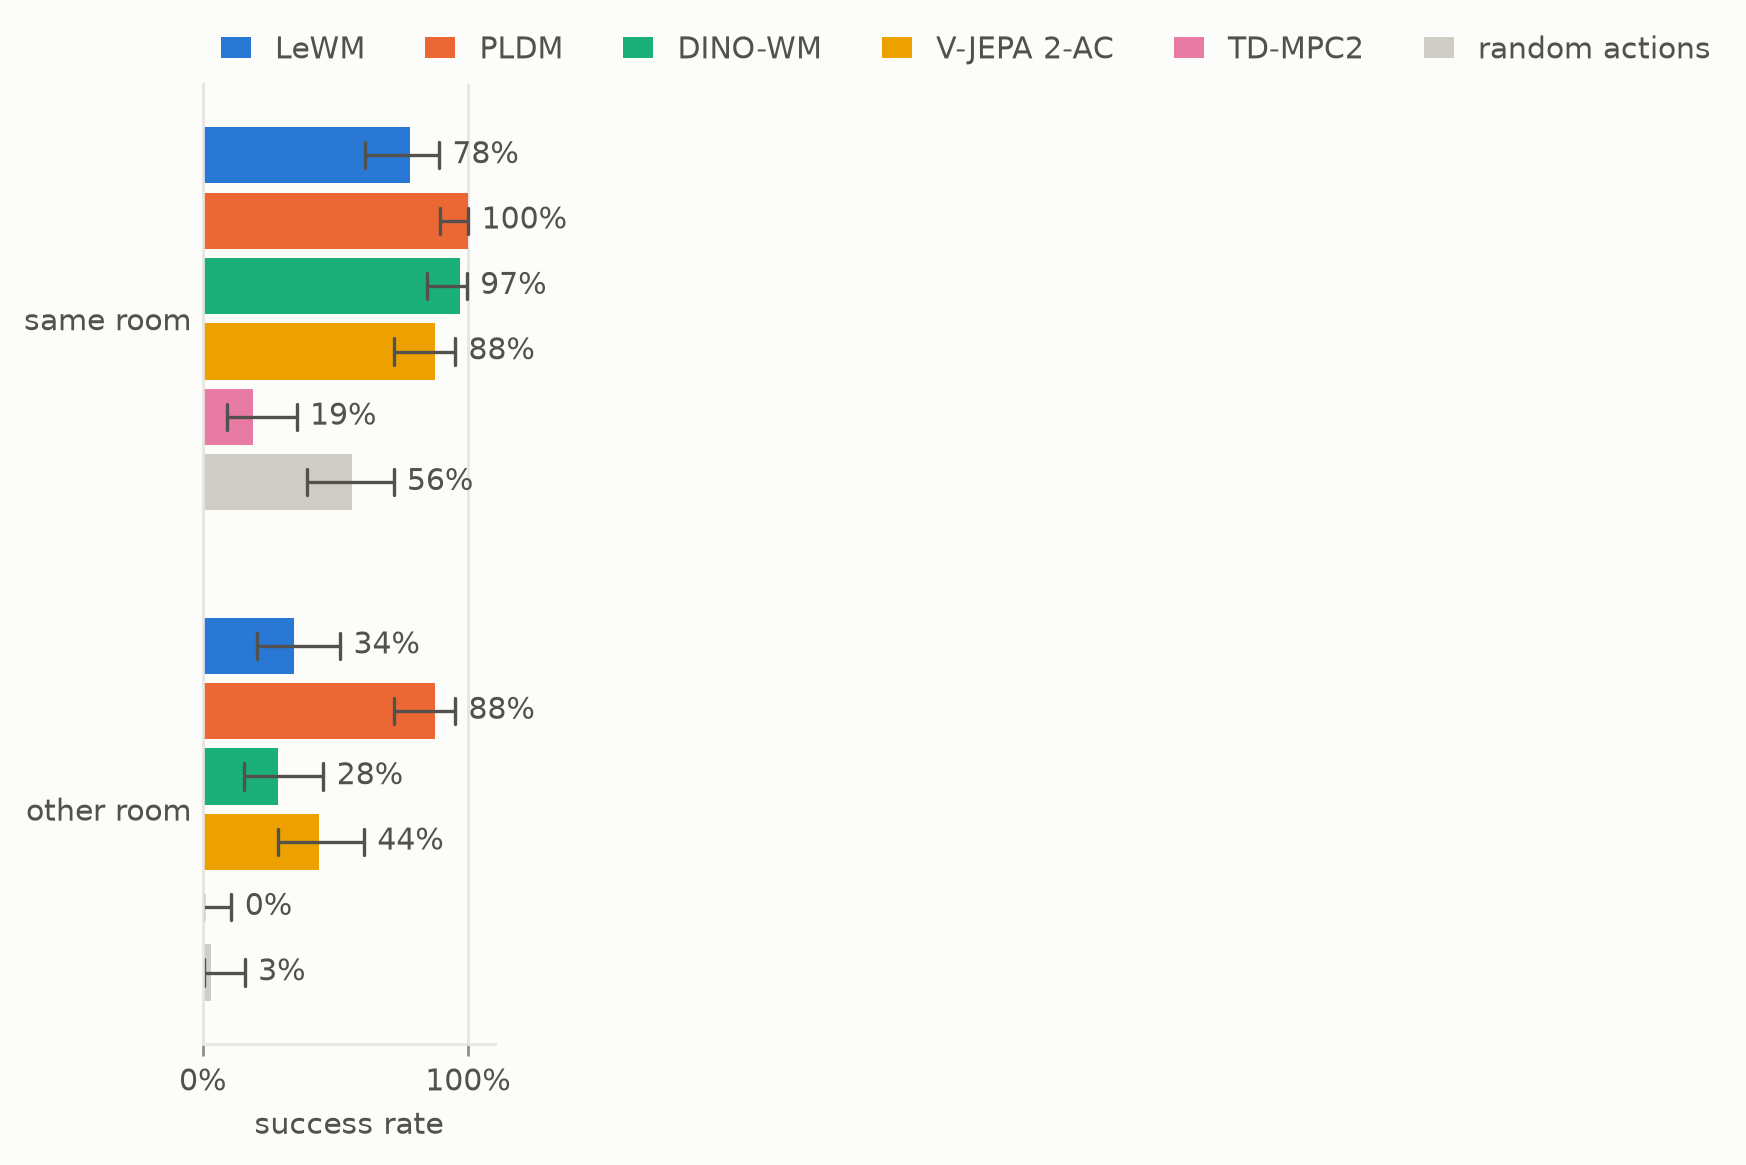

In [8]:
plots.bars({task: r.intervals() for task, r in results.items()}, xlabel="success rate", baseline="random actions")

## Summary
Success with its interval, training time and planning time per step, for each model:

In [9]:
print(f"{'':14s}{'same room':>20s}{'other room':>20s}{'train min':>11s}{'plan ms':>9s}")
for name in models:
    same, other = (results[t].intervals()[name] for t in ("same room", "other room"))
    print(f"{name:14s}{same!s:>20}{other!s:>20}{minutes[name]:11.1f}{1000 * results['other room'].seconds[name]:9.0f}")

                         same room          other room  train min  plan ms
LeWM                78% [61%, 89%]      34% [20%, 52%]        5.6     1224
PLDM              100% [89%, 100%]      88% [72%, 95%]       13.8       23
DINO-WM             97% [84%, 99%]      28% [16%, 45%]        7.5    17301
V-JEPA 2-AC         88% [72%, 95%]      44% [28%, 61%]       25.4    41768
TD-MPC2              19% [9%, 35%]        0% [0%, 11%]        3.1       14
